# Petrophys: first plot, then interpretation

Start with a bundled LAS. No formation table, lithology file, Rw, or mineral assumptions are needed to view existing measurements.

This notebook teaches three distinct tasks: **read**, **plot**, and optionally **interpret**. It uses only public library APIs. Run cells from the top in a kernel containing this checkout's installed package. For installation and kernel selection, see [lesson 00](part_a_foundations/00_orientation_and_setup.ipynb).

In [1]:
%matplotlib inline

## 1. Plot a LAS in a few lines

The depth window is specific to the bundled 30/6-5 well, in metres. For another well, omit it initially or choose a window in that well's depth units.

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:390: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:390: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


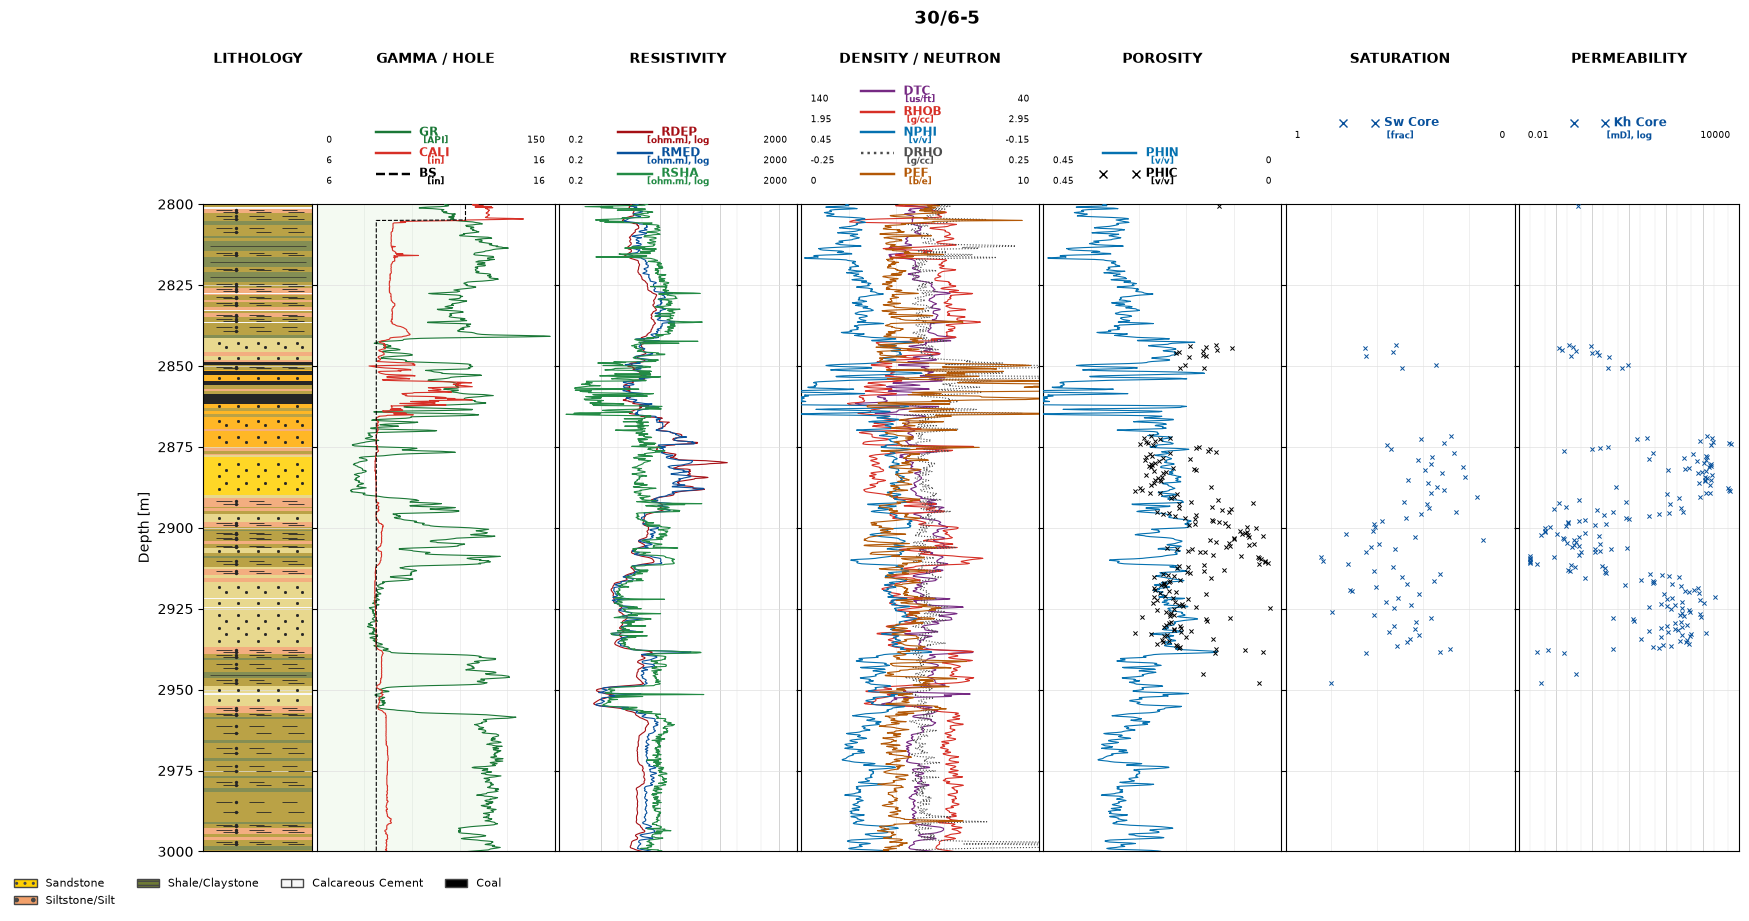

In [2]:
import petrophys as pp
well = pp.read(pp.sample("30_6-5"))
viewer = pp.plot(well, depth_range=(2800, 3000), figsize=(16, 9))
viewer.show()
viewer.close()

The viewer shows existing logs and core measurements; it does not calculate a missing `SW` curve. The **Sw Core** points are measured core saturation, not a continuous log-derived result.

The source well is unchanged by plotting. Core percentages are normalized on a display copy, with inferred conversions reported below.

In [3]:
raw_curves = tuple(well.curves)
print(well.name, well.top, well.bottom, well.depth_unit)
print("Existing SW curve:", well.get("SW") is not None)
print("Plot warnings:", viewer.warnings)
print("Omitted tracks:", viewer.diagnostics["omitted_tracks"])

30/6-5 176.60999 3556.08032 m
Existing SW curve: False
Plot warnings: ["SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units."]
Omitted tracks: []


## 2. Add optional formations or lithology

Either file may be omitted. The bundled companion files are example interpretations for this well. External intervals attached with `pp.read` are used by both plotting and subsequent interpretation. No manual numeric rock coding is required.

For your own files, use [the own-data tutorial](own_data.ipynb) and the downloadable [input templates](../docs/input_templates.rst). Do not use template example rows as picks for your well.

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:390: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:390: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


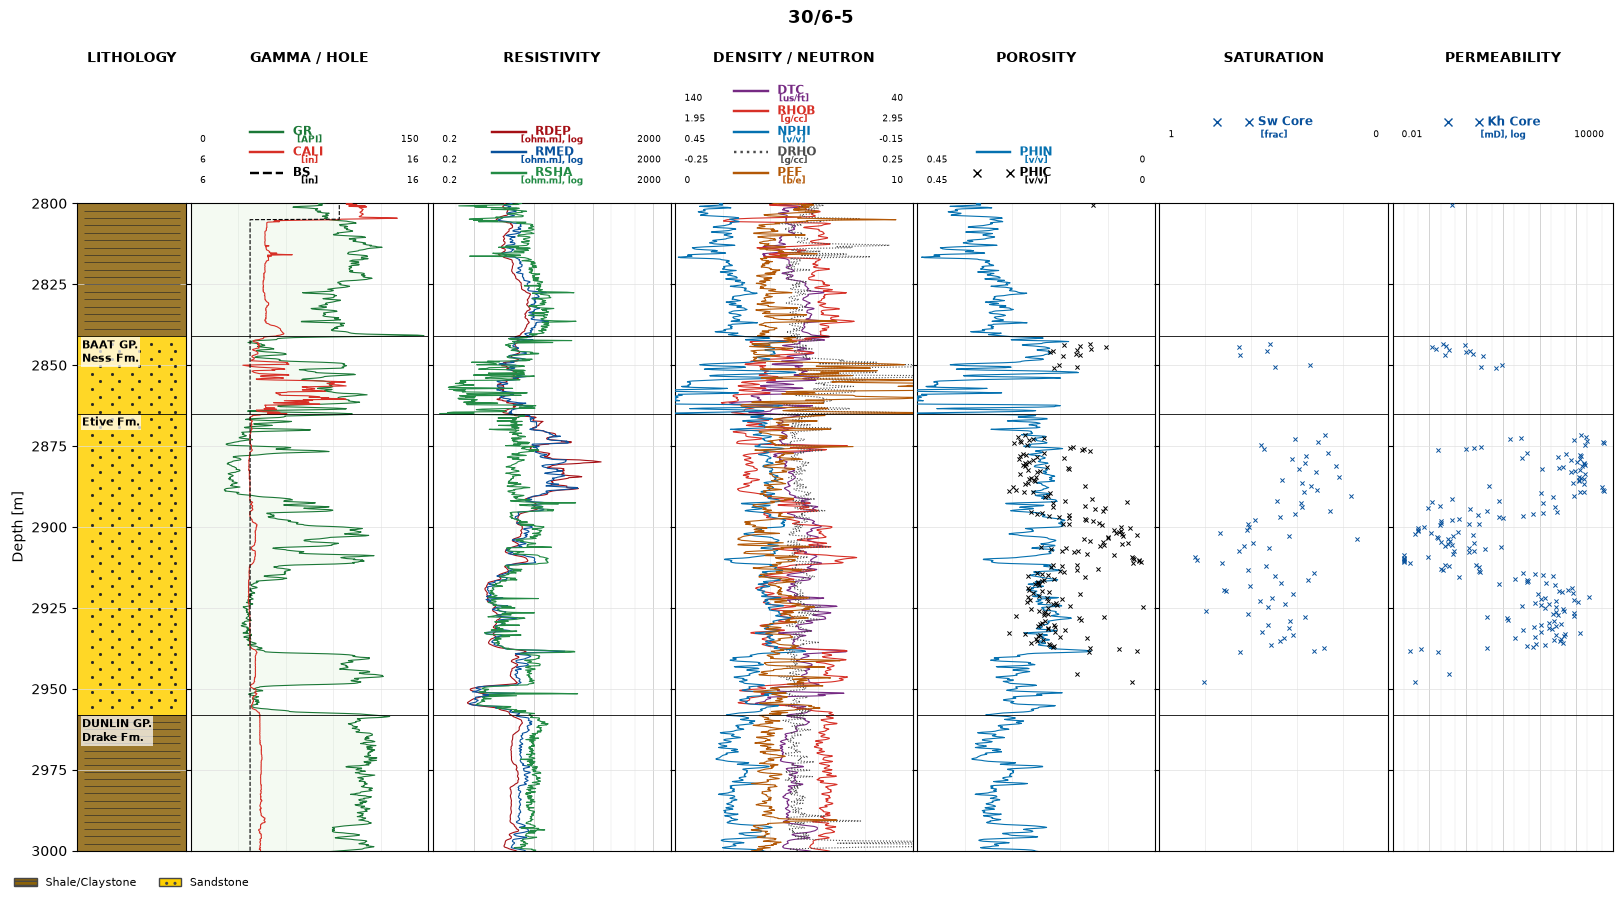

Lithology source: external
Formation rows: 20
Suppressed labels: []


In [4]:
context_well = pp.read(
    pp.sample("30_6-5"),
    formations=pp.sample("formations_30_6-5"),
    lithology=pp.sample("lithology_30_6-5"),
)
context_viewer = pp.plot(context_well, depth_range=(2800, 3000), figsize=(16, 9))
context_viewer.show()
context_viewer.close()
print("Lithology source:", context_viewer.diagnostics["lithology_source"])
print("Formation rows:", context_viewer.diagnostics["formations"]["accepted_rows"])
print("Suppressed labels:", context_viewer.diagnostics["suppressed_formation_labels"])

## 3. Interpret, separately from plotting

Below, `Rw = 0.070 ohm.m at 230 F` is an **illustrative teaching assumption**, not a recommendation for another well. Temperature basis, fluid properties, rock models and cutoffs must be justified for your application. No default Rw is silently introduced when supported inputs are unavailable.

This run deliberately uses the LAS-only `well`. External geology is not required. Embedded vendor lithology may be used when available; without it, supported logs can drive mineral inversion.

`pp.interpret` copies the well by default. The lower-level `run_dynamic_workflow` API still mutates its input.

In [5]:
result = pp.interpret(well, rw=0.070, rw_meas_temp_f=230.0)
result.raise_for_errors()
assert result.well is not well
assert tuple(well.curves) == raw_curves
print("Status:", result.status)
print("Skipped steps:", result.specific_steps_skipped)
print("Warnings:", result.warnings)

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:390: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:390: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


Status: interpreted
Skipped steps: {'spectral_gamma': 'Needs processed spectral gamma curves (potassium, thorium or uranium)', 'elemental_spectroscopy': 'Needs processed elemental concentration or yield curves', 'hc_correction': 'apply_hc_correction=False (hydrocarbon correction is opt-in)', 'porosity_refinement': 'No computed lithology log (LITHO) was produced to refine porosity by rock type'}
Warnings: ['Auto lithology resolved via vendor_log (83% of 10732 samples): matrix_type=sandstone, lithology=clastic']


## 4. Inspect decisions, not just success

A successful run can still have skipped calculations. Read the selected methods, assumptions and missing inputs before using its outputs. Use `raise_on_error=True` during interpretation when you want the original exception for debugging.

In [6]:
trace = result.to_dataframe()
trace[["Step", "Status", "Method", "Input Curves", "Output Curves"]]

,Step,Status,Method,Input Curves,Output Curves
0,normalization,OK,curve_alias_and_unit_standardization,"BS, CALI, DRHO, DTC, DTE, GDEN, GR, KH_CORE, K...","BS, CALI, DRHO, DTC, DTE, GDEN, GR, KH_CORE, K..."
1,input_context,OK,validated_geology_selection,,
2,temperature,OK,linear_gradient_from_BHT,,TEMP
3,bad_hole,OK,caliper_drho_flags,"CALI, BS, DRHO, RHOB, PEF",BAD_HOLE
4,vclay,OK,linear,"GR, SP, NPHI, RHOB","VCL, VCLAY, VCL_GR, VCLGR, VCL_SP, VCLSP, VCL_..."
5,rcl,OK,lithology_shale_median_rt,"RDEP, VCL",
6,rmf,OK,las_metadata_assumed_reference_temperature,,RMF
7,porosity,OK,component_based,"NPHI, RHOB, DTC, VCL","PHIN, PHID, PHIS, PHIT, PHIE, PHI_SEC"
8,lithology,OK,multi_mineral_solver,"RHOB, VCL, NPHI, PHIE, PEF, DTC","VQUAR, VCALC, VDOLO, VANHY, MMQC"
9,core_correction,OK,same_well_core_correction,PHIE,"PHIE_CC, PERM_CC"


In [7]:
summary = result.to_trace_dict(include_curves=["VCL", "PHIE", "SW", "PERM"])
summary["status"], summary["curve_summaries"]

('interpreted',
 {'VCL': {'unit': 'v/v',
   'description': 'Clay Volume',
   'data': {'type': 'ndarray',
    'shape': [22176],
    'size': 22176,
    'sample': [0.0, 0.0, 0.0, 0.0, 0.0],
    'finite_count': 22176,
    'nan_count': 0,
    'inf_count': 0,
    'min': 0.0,
    'max': 1.0,
    'mean': 0.17114464145201924,
    'p05': 0.0,
    'p50': 0.12552595133927164,
    'p95': 0.5934519685546051}},
  'PHIE': {'unit': 'v/v',
   'description': 'Effective Porosity',
   'data': {'type': 'ndarray',
    'shape': [22176],
    'size': 22176,
    'sample': [0.5, 0.5, 0.5, 0.5, 0.5],
    'finite_count': 22176,
    'nan_count': 0,
    'inf_count': 0,
    'min': 0.0,
    'max': 0.5,
    'mean': 0.3201395216060196,
    'p05': 0.06432094588837042,
    'p50': 0.390378005176759,
    'p95': 0.49360313272754114}},
  'SW': {'unit': 'frac',
   'description': 'Water Saturation (archie+indonesia+dual_water; source input priority)',
   'data': {'type': 'ndarray',
    'shape': [22176],
    'size': 22176,
    's

## 5. Plot the interpreted result

`result.plot` and `pp.plot` return the same `LogViewer` type, with `show`, `save`, `close`, `fig`, `axes`, and `diagnostics`. A computed saturation curve can now appear alongside the core observations.

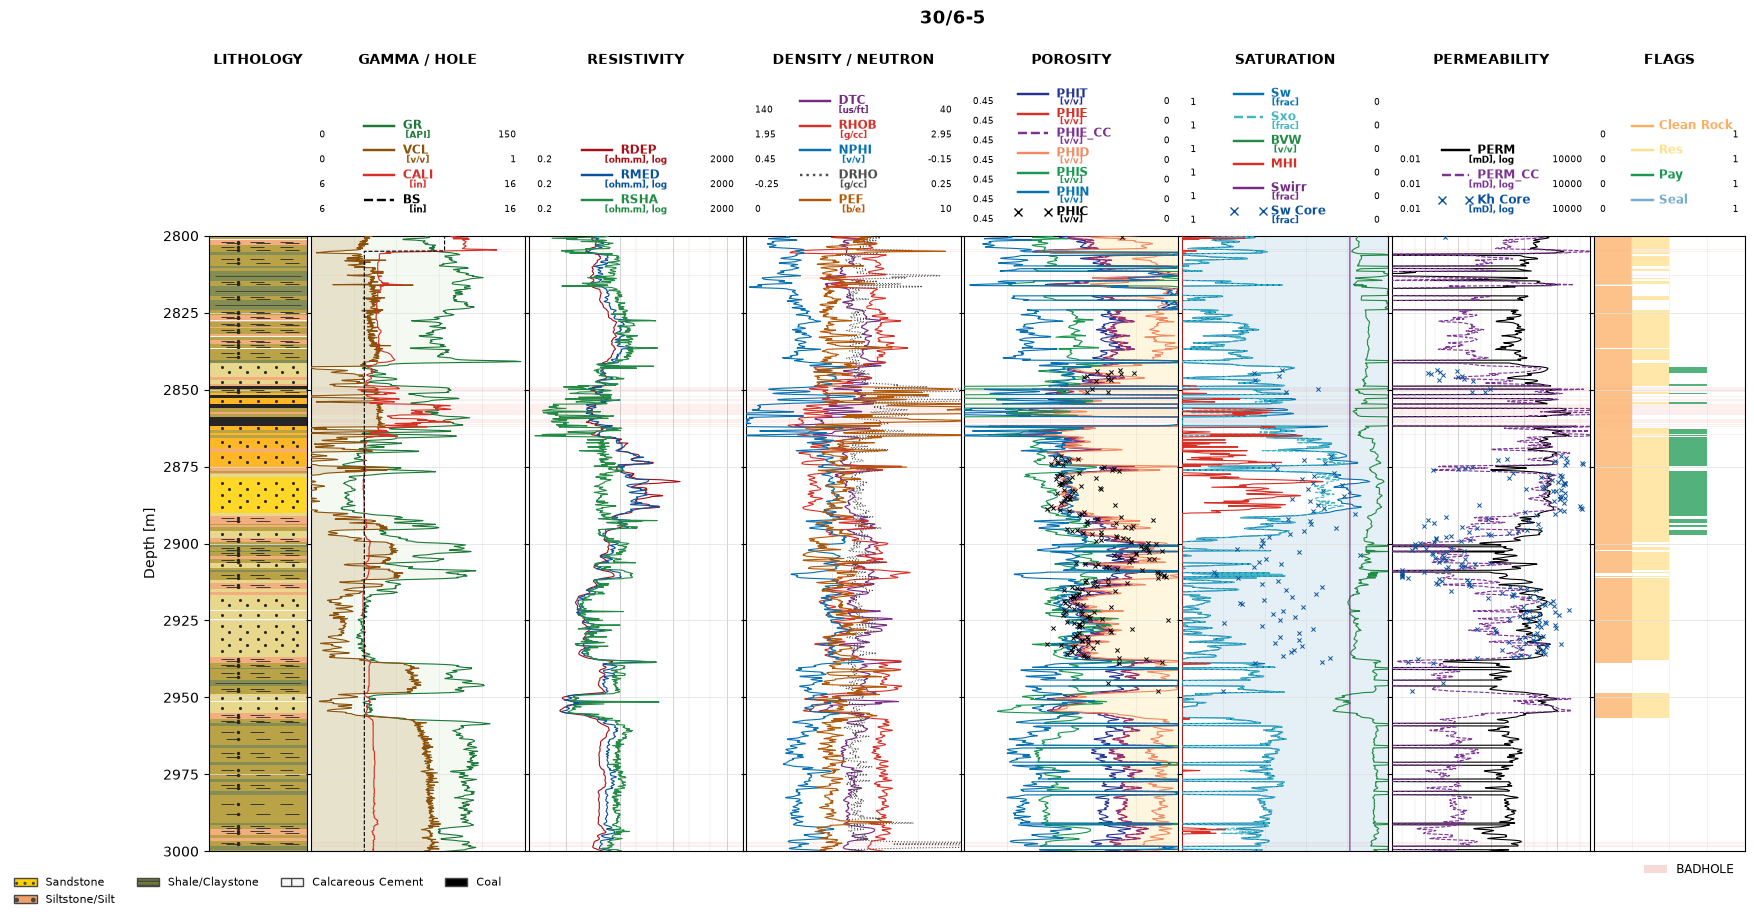

In [8]:
interpreted_viewer = result.plot(depth_range=(2800, 3000), figsize=(16, 9))
interpreted_viewer.show()
interpreted_viewer.close()

## Use your own data or go deeper

- Replace `pp.sample("30_6-5")` with your LAS path. Plot it before adding interpretation assumptions.
- Follow [Your Own Data](own_data.ipynb) for CSV/TSV logs, geology templates, Excel sheets, column mappings and depth checks.
- See [lesson 05](part_a_foundations/05_lithology_and_mineral_solver.ipynb) for the mineral solver without external geology.
- See [lesson 10](part_b_advanced/10_dynamic_workflow_glass_box.ipynb) for detailed configuration, source selection and traces.
- See [lesson 11](part_b_advanced/11_formation_and_interval_analysis.ipynb) for top-only picks, explicit bottoms and union-based totals.
- See [lesson 17](part_b_advanced/17_visualization_masterclass.ipynb) for track selection and advanced plot composition.
- NMR uses a specialist interface: [lesson 14](part_b_advanced/14_nmr_petrophysics.ipynb).